In [1]:
'''
make new efficiency data
'''

'\nmake new efficiency data\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp


import importlib
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
sat_df= pd.read_csv('/home/3155/satsofar')

In [16]:
np.unique(sat_df['filename'])

NameError: name 'sat_df' is not defined

In [39]:
num_images = 8
wid = 10
n = 50
size = num_images * n * 3 * 2 + 1  #multiply by 3 for the total total


In [11]:
72-35

37

In [68]:
importlib.reload(imp)

<module 'implantation_functions' from '/home/3155/rwe/implantation_functions.py'>

In [34]:
sat_df[sat_df['filename']=='ztf_20221020148032_000686_zg_c03_x_0011.']['quad'].values

array([4, 4, 4, 4])

ztf_20221020138241_000686_zi_c02_x_0029.fits.fz
trans xcoord etc:  (381, 58, 1.4, 6)
trans xcoord etc:  (381, 687, 1.01, 5)
trans xcoord etc:  (380, 1287, 1.01, 7)
trans xcoord etc:  (380, 1863, 1.01, 5)
trans xcoord etc:  (381, 2434, 1.005, 4)
trans xcoord etc:  (490, 43, 1.2, 7)
trans xcoord etc:  (490, 684, 1.5, 6)
trans xcoord etc:  (490, 1284, 10.0, 9)
trans xcoord etc:  (489, 1862, 1.1, 5)
trans xcoord etc:  (490, 2374, 7.0, 3)
trans xcoord etc:  (1445, 74, 1.2, 9)
trans xcoord etc:  (1444, 633, 5.0, 3)
trans xcoord etc:  (1445, 1212, 5.0, 8)
trans xcoord etc:  (1445, 1825, 10.0, 5)
trans xcoord etc:  (1444, 2423, 2.0, 5)
trans xcoord etc:  (1458, 96, 1.4, 6)
trans xcoord etc:  (1458, 687, 1.5, 6)
trans xcoord etc:  (1458, 1217, 1.3, 3)
trans xcoord etc:  (1457, 1830, 7.0, 8)
trans xcoord etc:  (1458, 2378, 1.5, 9)
trans xcoord etc:  (1589, 65, 1.5, 9)
trans xcoord etc:  (1590, 700, 1.1, 9)
trans xcoord etc:  (1589, 1195, 1.01, 3)
trans xcoord etc:  (1589, 1800, 1.01, 4)
trans xc

KeyboardInterrupt: 

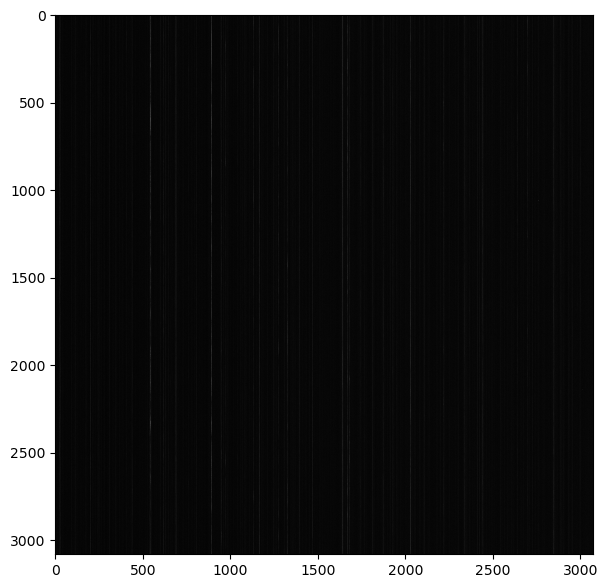

In [69]:
# HERES WHERE THE STUFF HAPPENS
path_to_save_pos = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/"
fpath_image = "/lustre/lrspec/ZTF_data/2022/1020/"
path_to_save_neg = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/"


seed = np.random.seed(20)  # so that i can keep the same random
# for the center of the transient - want at least half of the transient in the image
# center_values_new = np.random.randint(35, high=3035, size=size, dtype=int)
sigmas = np.random.randint(3, high=10, size=size, dtype=int)
intensities_pos = imp.get_intensities_pos_feb_eff(size, seed)
intensities_neg = imp.get_intensities_neg_feb_eff(size, seed)
counter = 0

for fname in np.unique(sat_df['filename']):
    
    image_filename = fname+'fits.fz'
    filename_start = image_filename[:40]
    image_filename_full = fpath_image + image_filename
    print(image_filename)
    hdul = fits.open(image_filename_full)
    for iteration in range(1, 5):
        if iteration in sat_df[sat_df['filename']==fname]['quad'].values: #don't use the ones with sats
            print(fname)
            print("skipping quad ", iteration)
            continue
        file1_array = hdul[iteration].data
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        plt.imshow(image)
        nrow, ncol = image.shape
    
        for thetype in ["pos", "neg"]:
            # print(type)
                
            if thetype=="pos":
                imagepath = (
                    path_to_save_pos
                    + "images/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + ".npy")
                
                infopath = (
                    path_to_save_pos
                    + "info/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + "_info.npy")
                

                stamps_implanted, stamp_info, = imp.implant_50_transients(
                image, sigmas, intensities_pos, counter, norm=False
                ) 
                np.save(imagepath, stamps_implanted)
                np.save(infopath, stamp_info)
                
            elif thetype=="neg":
                imagepath = (
                    path_to_save_neg
                    + "images/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + ".npy")
                
                infopath = (
                    path_to_save_neg
                    + "info/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + "_info.npy")
                

                stamps_implanted, stamp_info = imp.implant_50_transients(
                image, sigmas, intensities_neg, counter, norm=False
                ) 
                np.save(imagepath, stamps_implanted)
                np.save(infopath, stamp_info)



            counter += n 

In [37]:
imp.implant_n_transients?

Signature:
imp.implant_n_transients(
    image,
    n,
    sigmas,
    intensities,
    center_values,
    counter,
    norm,
    plot=False,
)
Docstring: like it says on the tin
File:      ~/rwe/implantation_functions.py
Type:      function

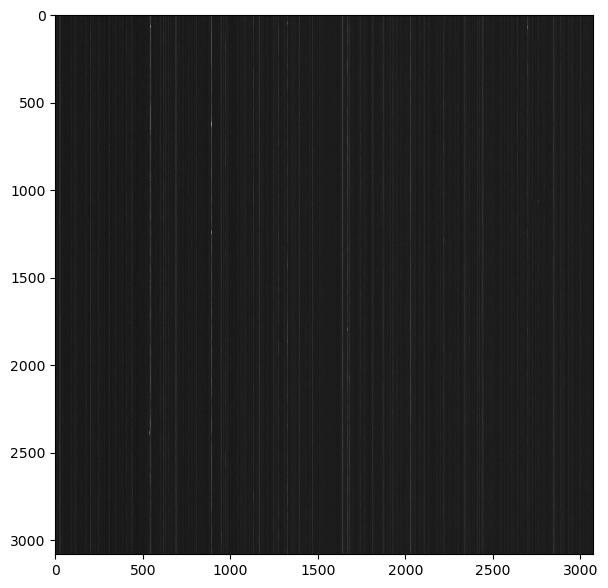

In [71]:
plt.imshow(np.sqrt(stamps_implanted))

In [58]:
iteration=4
np.random.randint(0,100)+35+iteration*(2900//5)

2428

In [60]:
0+35+0*(2900//5)

35

In [61]:
(2900//5)

580

In [75]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/info

ztf_20221020138241_000686_zi_c02_x_0029._1_info.npy
ztf_20221020138241_000686_zi_c02_x_0029._3_info.npy
ztf_20221020138241_000686_zi_c02_x_0029._4_info.npy
ztf_20221020148032_000686_zg_c03_x_0011._1_info.npy
ztf_20221020148032_000686_zg_c03_x_0011._2_info.npy
ztf_20221020148032_000686_zg_c03_x_0011._3_info.npy
ztf_20221020148032_000686_zg_c07_x_0013._1_info.npy
ztf_20221020148032_000686_zg_c07_x_0013._3_info.npy
ztf_20221020148032_000686_zg_c07_x_0013._4_info.npy
ztf_20221020148032_000686_zg_c16_x_0014._2_info.npy
ztf_20221020148032_000686_zg_c16_x_0014._3_info.npy
ztf_20221020148032_000686_zg_c16_x_0014._4_info.npy
ztf_20221020154120_000640_zi_c08_x_0014._2_info.npy
ztf_20221020154120_000640_zi_c08_x_0014._3_info.npy
ztf_20221020154120_000640_zi_c11_x_0015._2_info.npy
ztf_20221020154120_000640_zi_c11_x_0015._4_info.npy
ztf_20221020154120_000640_zi_c15_x_0028._1_info.npy
ztf_20221020154120_000640_zi_c15_x_0028._2_info.npy
ztf_20221020154120_000640_zi_c15_x_0028._4_info.npy
ztf_20221020

In [ ]:
# df_implants_pos = pd.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
# df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


In [76]:
os.listdir(path_to_save_pos+'info')

['ztf_20221020138241_000686_zi_c02_x_0029._4_info.npy',
 'ztf_20221020148032_000686_zg_c07_x_0013._3_info.npy',
 'ztf_20221020148032_000686_zg_c03_x_0011._1_info.npy',
 'ztf_20221020154120_000640_zi_c15_x_0028._2_info.npy',
 'ztf_20221020138241_000686_zi_c02_x_0029._3_info.npy',
 'ztf_20221020148032_000686_zg_c07_x_0013._4_info.npy',
 'ztf_20221020294271_000449_zr_c16_x_0020._1_info.npy',
 'ztf_20221020154120_000640_zi_c15_x_0028._4_info.npy',
 'ztf_20221020138241_000686_zi_c02_x_0029._1_info.npy',
 'ztf_20221020148032_000686_zg_c07_x_0013._1_info.npy',
 'ztf_20221020148032_000686_zg_c16_x_0014._2_info.npy',
 'ztf_20221020154120_000640_zi_c11_x_0015._2_info.npy',
 'ztf_20221020148032_000686_zg_c03_x_0011._3_info.npy',
 'ztf_20221020294271_000449_zr_c16_x_0020._2_info.npy',
 'ztf_20221020154120_000640_zi_c08_x_0014._2_info.npy',
 'ztf_20221020148032_000686_zg_c16_x_0014._4_info.npy',
 'ztf_20221020154120_000640_zi_c11_x_0015._4_info.npy',
 'ztf_20221020294271_000449_zr_c16_x_0020._3_inf

In [80]:
'ztf_20221020138241_000686_zi_c02_x_0029._4_info.npy'[41]

'4'

In [94]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = path_to_save_pos+'info'
path_to_save = path_to_save_pos

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path)
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    infos = np.load(os.path.join(folder_path, f))
    filename_start = f[:40]
    filename_quad = f[41]
    # print(info)
    if counter == 0:
        df_implants["filename"] = np.full(len(infos),filename_start)
        df_implants["row_from_implant"] = infos[:,0]
        df_implants["col_from_implant"] = infos[:,1]
        df_implants["A_from_implant"] = infos[:,2]
        df_implants["sig_from_implant"] = infos[:,3]
        df_implants["quad_from_implant"] = np.full(len(infos),filename_quad)
        counter = 1
    else:
        print("adding")
        df_implants2 = pd.DataFrame([])
        df_implants2["filename"] = np.full(len(infos),filename_start)
        df_implants2["row_from_implant"] = infos[:,0]
        df_implants2["col_from_implant"] = infos[:,1]
        df_implants2["A_from_implant"] = infos[:,2]
        df_implants2["sig_from_implant"] = infos[:,3]
        df_implants2["quad_from_implant"] = np.full(len(infos),filename_quad)
        df_implants = pd.concat(
           [df_implants2, df_implants], ignore_index=True
                   )
# df_implants_neg = df_implants
    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding


In [89]:
1/np.sqrt(5)

0.4472135954999579

In [99]:
np.unique(df_implants['A_from_implant'], return_counts=True)

(array([0.2  , 0.3  , 0.4  , 0.5  , 0.6  , 0.7  , 0.8  , 0.9  , 0.95 ,
        0.99 , 0.995]),
 array([103,  99, 102,  94,  98,  98,  98, 101, 103, 103, 101]))

In [96]:
df_implants.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/df_implants_pos")
# df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


In [97]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = path_to_save_neg+'info'
path_to_save = path_to_save_neg

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path)
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    infos = np.load(os.path.join(folder_path, f))
    filename_start = f[:40]
    filename_quad = f[41]
    # print(info)
    if counter == 0:
        df_implants["filename"] = np.full(len(infos),filename_start)
        df_implants["row_from_implant"] = infos[:,0]
        df_implants["col_from_implant"] = infos[:,1]
        df_implants["A_from_implant"] = infos[:,2]
        df_implants["sig_from_implant"] = infos[:,3]
        df_implants["quad_from_implant"] = np.full(len(infos),filename_quad)
        counter = 1
    else:
        print("adding")
        df_implants2 = pd.DataFrame([])
        df_implants2["filename"] = np.full(len(infos),filename_start)
        df_implants2["row_from_implant"] = infos[:,0]
        df_implants2["col_from_implant"] = infos[:,1]
        df_implants2["A_from_implant"] = infos[:,2]
        df_implants2["sig_from_implant"] = infos[:,3]
        df_implants2["quad_from_implant"] = np.full(len(infos),filename_quad)
        df_implants = pd.concat(
           [df_implants2, df_implants], ignore_index=True
                   )
df_implants.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/df_implants_neg")
# df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")

    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding


In [103]:
"ztf_20221020138241_000686_zi_c02_x_0029._1.npy"[:42]

'ztf_20221020138241_000686_zi_c02_x_0029._1'

In [105]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange/df_concat')

(array([2956.,    0.,    0., 3799.,    0.,    0., 6273.,    0.,    0.,
        4011.]),
 array([1. , 1.3, 1.6, 1.9, 2.2, 2.5, 2.8, 3.1, 3.4, 3.7, 4. ]),
 <BarContainer object of 10 artists>)

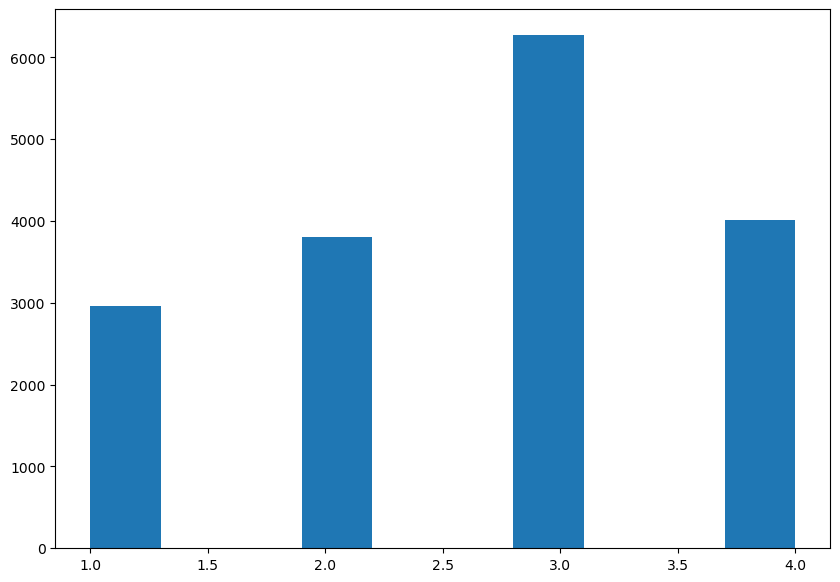

In [108]:
plt.hist(concat['quad'])

In [2]:
offcenter_pos = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_offset_small_patient/df_matched')

In [7]:
offcenter_neg = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_offset_small_patient/df_matched')

In [7]:
newrange_pos = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange/df_matched')

In [3]:
newrange_neg = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_newrange/df_matched')

In [18]:
half_neg = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_offset_half/df_matched')
half_pos = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_offset_half/df_matched')

In [4]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/df_implants_neg")


In [5]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [6]:
import precision_recall as pr

In [26]:
cut_len, implant_len = get_efficiency(df_pos_dup, df_implants_pos, 20, posneg='pos')
print("pos dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos_dup)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg_dup, df_implants_neg, 20, posneg='neg')
print("neg dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg_dup)):.1f} %")

print("cut")

cut_len, implant_len = get_efficiency(df_pos_dup[df_pos_dup['Diff']<5], df_implants_pos, 20, posneg='pos')
print("pos dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos_dup[df_pos_dup['Diff']<10])):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg_dup[df_neg_dup['Diff']<5], df_implants_neg, 20, posneg='neg')
print("neg dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg_dup[df_neg_dup['Diff']<10])):.1f} %")



pos dup 60.6 %, with precision 26.4 %
neg dup 63.5 %, with precision 9.9 %
cut
pos dup 60.3 %, with precision 27.1 %
neg dup 61.5 %, with precision 10.1 %


In [31]:
cut_len, implant_len = get_efficiency(df_pos_dup, df_implants_pos, 20, posneg='pos')
print("pos dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos_dup)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg_dup, df_implants_neg, 20, posneg='neg')
print("neg dup", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg_dup)):.1f} %")


cut_len, implant_len = get_efficiency(df_pos, df_implants_pos, 20, posneg='pos')
print("pos newrange", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg, df_implants_neg, 20, posneg='neg')
print("neg newrange", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg)):.1f} %")
   
# cut_len, implant_len = get_efficiency(offcenter_pos, df_implants_pos, 20, posneg='pos')
# print("pos offcenter", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(offcenter_pos)):.1f} %")
  
# cut_len, implant_len = get_efficiency(offcenter_neg, df_implants_neg, 20, posneg='neg')
# print("neg offcenter", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(offcenter_neg)):.1f} %")
  
    
# cut_len, implant_len = get_efficiency(half_pos, df_implants_pos, 20, posneg='pos')
# print("pos offcenter bigger", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(half_pos)):.1f} %")
  
# cut_len, implant_len = get_efficiency(half_neg, df_implants_neg, 20, posneg='neg')
# print("neg offcenter bigger", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(half_neg)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_pos_offset, df_implants_pos, 20, posneg='pos')
print("pos offcenter biggest", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos_offset)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg_offset, df_implants_neg, 20, posneg='neg')
print("neg offcenter biggest", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg_offset)):.1f} %")
  
    
cut_len, implant_len = get_efficiency(df_pos_sat, df_implants_pos, 20, posneg='pos')
print("pos offcenter sat", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_pos_sat)):.1f} %")
  
cut_len, implant_len = get_efficiency(df_neg_sat, df_implants_neg, 20, posneg='neg')
print("neg offcenter sat", f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df_neg_sat)):.1f} %")


pos dup 60.6 %, with precision 26.4 %
neg dup 63.5 %, with precision 9.9 %
pos newrange 73.8 %, with precision 4.8 %
neg newrange 69.2 %, with precision 2.3 %
pos offcenter biggest 46.5 %, with precision 42.0 %
neg offcenter biggest 47.3 %, with precision 31.6 %
pos offcenter sat 48.4 %, with precision 39.0 %
neg offcenter sat 53.5 %, with precision 43.2 %


(-10.0, 10.0)

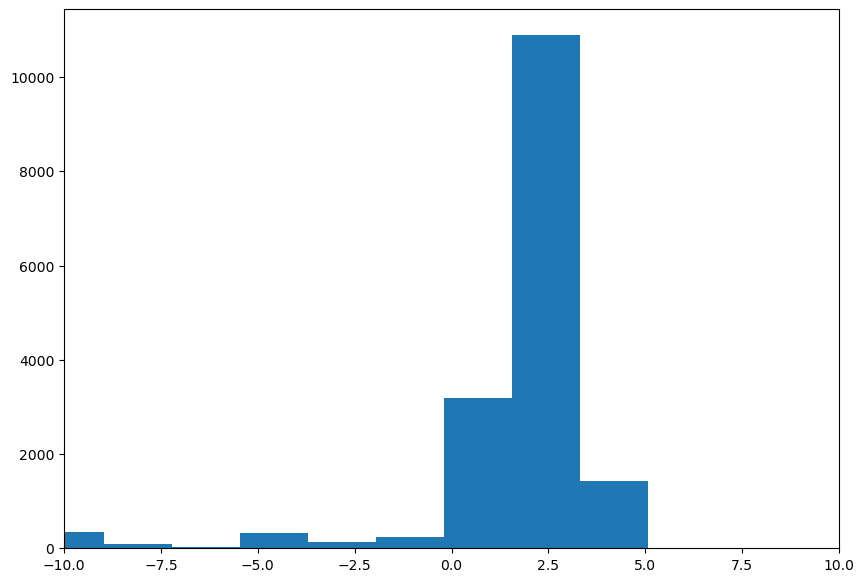

In [17]:
plt.hist(newrange['Diff'], bins=300)
plt.xlim(-10,10)

In [9]:
df_pos = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange/df_matched')
df_neg = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_newrange/df_matched')

In [10]:
df_pos_dup = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_dup_3/df_matched')
df_neg_dup = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_dup_3/df_matched')

In [27]:
df_pos_offset = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_offset/df_matched')
df_neg_offset = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_offset/df_matched')

In [28]:
df_pos_sat = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_offset_sat/df_matched')
df_neg_sat = pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_offset_sat/df_matched')

In [12]:
def get_histtable(df):
    '''
    sort by the thing you want, it keeps the last (biggest)
    '''
    data = df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")["A_from_implant"]
    print(len(data))
    return data

def make_bar(df, label, binbounds, ax, alpha=.5):
    data = get_histtable(df)
    hist, bin_edges = np.histogram(data,binbounds)
    return ax.bar(range(len(hist)),hist,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist)], alpha=alpha, label=label)


both = pd.concat([df_neg[df_neg['type']=='neg'],df_pos[df_pos['type']=='pos']], ignore_index=True)


binbounds = list(np.unique(np.concatenate([df_implants_neg["A_from_implant"],
                                           [1],
                                           df_implants_pos["A_from_implant"],
                                           [np.unique(df_implants_pos["A_from_implant"])[-1]+.002]]))-.001)


1822
1553
1218
1054
1147


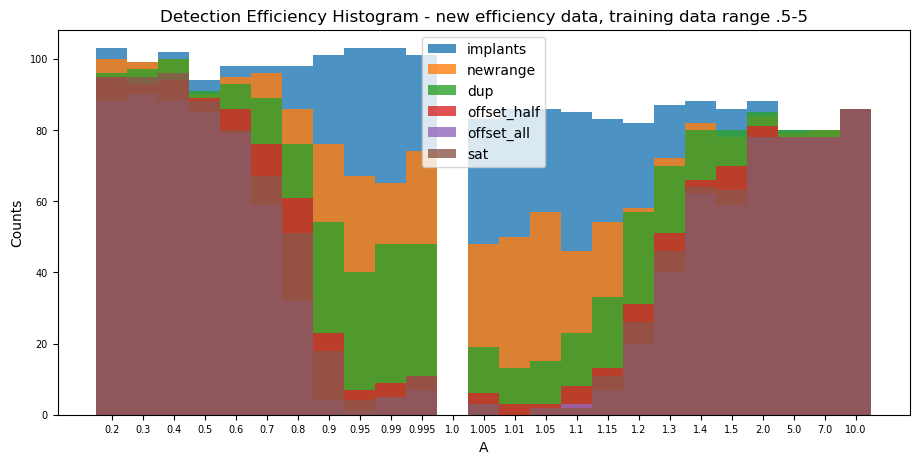

In [29]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = .8

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")



make_bar(both, "newrange", binbounds, ax, alpha=alpha)
both3 = pd.concat([df_neg_dup[df_neg_dup['type']=='neg'],df_pos_dup[df_pos_dup['type']=='pos']], ignore_index=True)
# both4 = pd.concat([offcenter_neg[offcenter_neg['type']=='neg'],offcenter_pos[offcenter_pos['type']=='pos']], ignore_index=True)

both4 = pd.concat([half_neg[half_neg['type']=='neg'],half_pos[half_pos['type']=='pos']], ignore_index=True)
make_bar(both3, "dup", binbounds, ax, alpha=alpha)
make_bar(both4, "offset_half", binbounds, ax, alpha=alpha)

both5 = pd.concat([df_neg_offset[df_neg_offset['type']=='neg'],df_pos_offset[df_pos_offset['type']=='pos']], ignore_index=True)
both6 = pd.concat([df_neg_sat[df_neg_sat['type']=='neg'],df_pos_sat[df_pos_sat['type']=='pos']], ignore_index=True)
make_bar(both5, "offset_all", binbounds, ax, alpha=alpha)
make_bar(both6, "sat", binbounds, ax, alpha=alpha)


# make_bar(both, "offset partial training", binbounds, ax, alpha=alpha)


# make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>5], "detection size>4", binbounds, ax, alpha=alpha)

ax.tick_params(axis='both', which='major', labelsize=7)

plt.title("Detection Efficiency Histogram - new efficiency data, training data range .5-5")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()



In [29]:
rff.inspect_stamp_and_map?

Signature:
rff.inspect_stamp_and_map(
    df,
    index,
    eff=True,
    neweff='new_eff_data/',
    posneg=None,
    size=10,
    column=None,
    nn_or_imp='nn',
    thr=True,
    star=False,
    direcname='1020',
    pdirec='predsarrays',
)
Docstring: for efficiency data
File:      ~/rwe/review_findings_functions.py
Type:      function

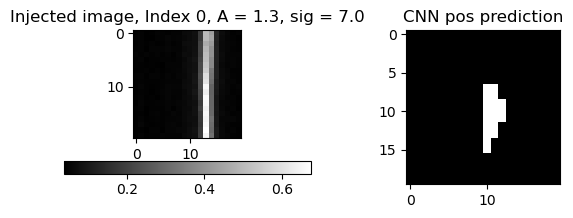

In [31]:
rff.inspect_stamp_and_map(df_pos, 0, posneg='pos', pdirec='predsarrays_newrange')

In [43]:
df_pos[20:30]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
20,20,20,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,85.230769,413.615385,13,425.0,136.0,...,6,3,148.0,[15],0.0,114.342473,110.0,537.0,7.00,7.0
21,21,21,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,83.000000,1726.000000,7,1738.0,1302.0,...,4,3,180.0,[],0.0,66.370174,59.0,1679.0,1.40,7.0
22,22,22,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,91.250000,1659.650000,20,1672.0,1726.0,...,1,3,129.0,[17 26],1.0,43.272220,59.0,1679.0,1.40,7.0
23,23,23,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,91.777778,2468.555556,9,2481.0,1059.0,...,3,3,204.0,[18 28],1.0,220.637264,111.0,2699.0,1.30,7.0
24,24,24,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,99.666667,195.166667,18,207.0,2284.0,...,5,3,172.0,[],0.0,331.833501,110.0,537.0,7.00,7.0
25,25,25,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,111.736486,2154.736486,148,2165.0,2847.0,...,2,3,153.0,[29],0.0,56.296786,111.0,2220.0,1.15,8.0
26,26,26,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,104.000000,1659.416667,12,1672.0,1726.0,...,1,3,129.0,[22 30],1.0,55.828669,59.0,1679.0,1.40,7.0
27,27,27,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,105.789474,1725.421053,19,1738.0,1302.0,...,4,3,180.0,[],0.0,80.052355,59.0,1679.0,1.40,7.0
28,28,28,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,105.500000,2468.500000,12,2481.0,1059.0,...,3,3,204.0,[23 31],1.0,220.545914,111.0,2699.0,1.30,7.0
29,29,29,ztf_20221020138241_000686_zi_c02_x_0029.,3,pos,114.500000,2161.000000,6,2165.0,2847.0,...,2,3,153.0,[25],1.0,50.825682,111.0,2220.0,1.15,8.0


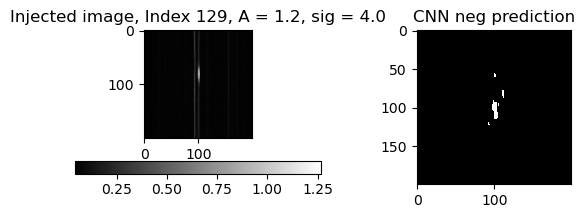

In [22]:
df = half_pos

index = 129
posneg='pos'
pdirec='predsarrays_newrange'
wid = 10
eff=True
neweff="new_eff_data/"
size=100
column=None
nn_or_imp='nn'
thr=True
star=False
direcname='1020'


if eff==True:
    if posneg==None:
        posneg = df.loc[index, "type"]
        print("Need posneg if you want to see the correct pimg...")
    if posneg=="pos":
        extension = "_1_implanted_pos.npy"
        if neweff=="new_eff_data/":
            extension = "_"+str(df.loc[index, "quad"])+".npy"
        
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/'+neweff+'full_image_implantations_pos/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_pos/"+pdirec+"/"
    elif posneg=="neg":
        extension = "_1_implanted_neg.npy"
        if neweff=="new_eff_data/":
            extension = "_"+str(df.loc[index, "quad"])+".npy"
        
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/'+neweff+'full_image_implantations_neg/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_neg/"+pdirec+"/"
    
    else:
        print("POSNEG ISSUE")
    fname = df.loc[index]["filename"] + extension
else:
    posneg = df.loc[index, 'type']

fig, ax = plt.subplots(1, 2, figsize=(7,2))


row = int(df.loc[index]["row_from_nn"])+wid
col = int(df.loc[index]["col_from_nn"])+wid

        
if eff:
    path = fpath + fname 
    array = np.load(path)
    imj = ax[0].imshow(
                
                    array[
                        row - size : row + size ,
                        col  - size : col  + size,
                    ]
                
                )
else:
    imj = ax[0].imshow(sobels_to_array(df.loc[index, 'stamp']))
                
nrow, ncol = 3080, 3072 
if eff==True:
    pfile = df.loc[index]["filename"]+"_extraction_predsarray_1_predsarray.npy"
    if neweff=="new_eff_data/":
        pfile = df.loc[index]["filename"]+"_" + str(df.loc[index]["quad"])+"_predsarray.npy"
    predsarray = np.load(ppath+pfile)
    if df.loc[index, "type"]=="pos":
        pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    else:
        pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)



if thr:
    ax[1].imshow(
    
                pimg[
                    col - size  - wid : col + size - wid,
                    row  - size - wid: row  + size - wid,
                ].T>.9999
            )
else:
    ax[1].imshow(
    
                pimg[
                    col - size  - wid: col + size - wid,
                    row  - size - wid: row  + size - wid,
                ].T
            )
    ax[2].imshow(
    
                pimg[
                    col - size  - wid: col + size - wid,
                    row  - size - wid : row  + size - wid,
                ].T>.9999
            )
    ax[2].set_title("CNN Thresholded")
if star==True:
             starpos = df.loc[index]['closest_x']
             ax[0].scatter(starpos- (col - size  + wid), 10)

if eff==True:
    ax[0].annotate(
    "Injection",
    xy=(  df["row_from_implant"].loc[index]-col+size,df["col_from_implant"].loc[index]-row+size),
    xytext=(size+3*size/4, size/2),  
    arrowprops=dict(
        facecolor="red",
        edgecolor="red",
        # shrink=1.0,
        # headlength=5,
        # headwidth=3,
    ),
    color="white",
    fontsize=10,
    ha="center",
    # va="top",
    rotation=0,
    zorder=10,
)
    ax[0].set_title("Injected image, Index "+str(index)+ ", A = "+str(df["A_from_implant"].loc[index])+", sig = "+str(df["sig_from_implant"].loc[index]))
else:
    ax[0].set_title("Injected image, Index "+str(index))
    
ax[1].set_title("CNN "+str(df.loc[index, "type"])+" prediction")
    # ax[2].set_title("CNN pos prediction")
    # print(df["row_from_implant"].iloc[index], col, df["col_from_implant"].iloc[index], row)
fig.colorbar(imj, orientation='horizontal')
plt.show()

In [66]:
if 1==1:
    if posneg=="neg":
        extension="_neg"
    elif posneg=="pos":
        extension="_pos"
    row_from_implant = {}
    col_from_implant = {}
    A_from_implant = {}
    sig_from_implant = {}
    dist_to_implant = {}
    # i=0
    for (filename, quad), group in df.groupby(['filename', 'quad']):   
        # for quad in np.unique(group['quad']):
        # infopath = (
        #     "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_"+posneg+"/info/"
        #     + str(filename)
        #     + "_"
        #     + str(1)
        #     + "_implanted_info"+extension+".npy"
        # )
        infopath = (
            "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_"+posneg+"/info/"
            + str(filename)
            + "_"
            + str(quad)+"_info.npy"
        )
        info = np.load(infopath)
        print(info)
        break
        # break      
            
#             for idx in group.index:
#                 distance_y = np.abs(df.loc[idx,"row_from_nn"] + 10 - info[:,1])
#                 distance_x = np.abs(df.loc[idx,"col_from_nn"] + 10 - info[:,0])
#                 total = np.sqrt(distance_y**2 + distance_x**2)
#                 closest_idx_info = np.argmin(total)
#                 dist_to_implant[idx] = total[closest_idx_info]
#                 row_from_implant[idx] = info[closest_idx_info][1]
#                 col_from_implant[idx] = info[closest_idx_info][0]
#                 A_from_implant[idx] = info[closest_idx_info][2]
#                 sig_from_implant[idx] = info[closest_idx_info][3]
            
#     df["dist_to_implant"] = df.index.map(dist_to_implant)
#     df["row_from_implant"] = df.index.map(row_from_implant)
#     df["col_from_implant"] = df.index.map(col_from_implant)
#     df["A_from_implant"] = df.index.map(A_from_implant)
#     df["sig_from_implant"] = df.index.map(sig_from_implant)
#     return df

[[3.800e+02 1.100e+02 1.300e+00 6.000e+00]
 [3.810e+02 6.400e+02 1.150e+00 5.000e+00]
 [3.810e+02 1.284e+03 1.150e+00 7.000e+00]
 [3.800e+02 1.835e+03 1.300e+00 5.000e+00]
 [3.800e+02 2.362e+03 1.400e+00 4.000e+00]
 [4.900e+02 5.600e+01 1.050e+00 7.000e+00]
 [4.900e+02 6.270e+02 1.010e+00 6.000e+00]
 [4.900e+02 1.200e+03 1.100e+00 9.000e+00]
 [4.890e+02 1.816e+03 1.300e+00 5.000e+00]
 [4.890e+02 2.439e+03 5.000e+00 3.000e+00]
 [1.445e+03 7.500e+01 5.000e+00 9.000e+00]
 [1.445e+03 6.840e+02 1.400e+00 3.000e+00]
 [1.445e+03 1.201e+03 1.500e+00 8.000e+00]
 [1.445e+03 1.863e+03 1.100e+00 5.000e+00]
 [1.445e+03 2.377e+03 1.150e+00 5.000e+00]
 [1.458e+03 6.400e+01 1.010e+00 6.000e+00]
 [1.458e+03 6.500e+02 2.000e+00 6.000e+00]
 [1.458e+03 1.203e+03 1.050e+00 3.000e+00]
 [1.458e+03 1.868e+03 2.000e+00 8.000e+00]
 [1.458e+03 2.433e+03 2.000e+00 9.000e+00]
 [1.589e+03 7.400e+01 1.100e+00 9.000e+00]
 [1.590e+03 6.730e+02 1.050e+00 9.000e+00]
 [1.589e+03 1.254e+03 1.300e+00 3.000e+00]
 [1.589e+03

In [69]:
quad

1